# Mine new hard-negative crops — 22 October 2026
This workflow uses only `hard_negative_mining_22_10_26/source_recordings/`. Previous sources and outputs are not included. The previous notebook, including its settings and outputs, is preserved as `mine_hard_negatives_before_22_10_26.ipynb`. The batch table, review and exports use the same **any-model alarm union**.

Set the new model list below. Nothing is exported by default. Crops stay in the workspace until you choose how to add them to `data_22_10_26`. Open with the project Python kernel and run in order.

In [9]:
from pathlib import Path
import importlib
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'tap_recognition').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'tap_recognition').is_dir(), 'Open from repository root or main_notebooks/'
sys.path.insert(0, str(ROOT))
from notebooks_analysis import hard_negative_mining as mining
importlib.reload(mining)
torch.set_num_threads(2)

MINING_WORKSPACE = ROOT / 'hard_negative_mining_22_10_26'
INPUT_DIR = MINING_WORKSPACE / 'source_recordings'
OUTPUT_DIR = MINING_WORKSPACE / 'crops'
MODELS = {
    'best (1510d8(62))': {
        'checkpoint': ROOT / 'testing_checkpoints/1510d8(62)/best.pt',
        'left_threshold': 0.25, 'right_threshold': 0.25,
    },
    '(1510d8(52))': {
        'checkpoint': ROOT / 'testing_checkpoints/1510d8(52)/best.pt',
        'left_threshold': 0.30, 'right_threshold': 0.30,
    },
    '(1510d8(102))': {
        'checkpoint': ROOT / 'testing_checkpoints/1510d8(102)/best.pt',
        'left_threshold': 0.30, 'right_threshold': 0.30,
    },
}
RESET_AT_SEGMENTS = False  # Continuous negative sources; always reset between files.
FULL_INFERENCE_CHUNK_FRAMES = 4096


## 1. Inventory the new negative sources
The 14 originals were staged separately from the strict positive sources. `temp/` is not implicitly mixed into this workspace. You can inspect the inventory before defining models.

In [10]:
inventory = mining.recording_inventory(INPUT_DIR)
display(inventory)
models = {name: mining.load_mining_model(spec['checkpoint']) for name, spec in MODELS.items()}
print('Models:', ', '.join(models) or 'none configured yet')


,file,user,action,frames,recording_type,seconds,sample_rate_hz,sessions,annotated_events
0,imu_MiguelL_negative_mining_20261016_181256.csv,MiguelL,negative_mining,26573,hard_negative,265.73,100.0,1,0
1,imu_MiguelL_negative_mining_20261016_181656.csv,MiguelL,negative_mining,6266,hard_negative,62.66,100.0,1,0
2,imu_MiguelL_negative_mining_20261016_185825.csv,MiguelL,negative_mining,3372,hard_negative,33.72,100.0,1,0
3,imu_MiguelL_negative_mining_20261016_192227.csv,MiguelL,negative_mining,21286,hard_negative,212.86,100.0,1,0
4,imu_MiguelL_negative_mining_20261016_192452.csv,MiguelL,negative_mining,8866,hard_negative,88.66,100.0,1,0
5,imu_MiguelL_negative_mining_20261019_191450.csv,MiguelL,negative_mining,29376,hard_negative,293.76,100.0,1,0
6,imu_MiguelL_negative_mining_20261023_093141.csv,MiguelL,negative_mining,14848,hard_negative,148.48,100.0,1,0
7,imu_MiguelL_normal_usage_20261016_185740.csv,MiguelL,normal_usage,20348,normal_usage,203.48,100.0,1,0
8,imu_MiguelL_normal_usage_20261019_190215.csv,MiguelL,normal_usage,17374,normal_usage,173.74,100.0,1,0
9,imu_MiguelL_normal_usage_20261019_190909.csv,MiguelL,normal_usage,13889,normal_usage,138.89,100.0,1,0


Models: best (1510d8(62)), (1510d8(52)), (1510d8(102))


## 2. Batch mining and optional export
Set `BATCH_SOURCE_TYPES=['negative_mining']`, `['normal_usage']`, or both. The type filter applies to automatic selection and explicit `BATCH_FILES`. Mine/export one type, change crop/context/gap/cooldown settings, then rerun for the other type if they need different styles. Existing exports are not removed.

Every selected model uses its own side thresholds; the resulting alarm union is thinned once using the gap/overlap settings. `SAVE_ALL_BATCH_CROPS=True` saves every candidate without individual review. Each crop contains raw sensor data, empty negative labels and source/model provenance.

In [13]:
BATCH_FILES = []
BATCH_SELECT_ALL = True
BATCH_SOURCE_TYPES = ['negative_mining']
BATCH_MODELS = list(MODELS)
BATCH_MIN_GAP_FRAMES = 100
BATCH_ALLOW_OVERLAPPING_CROPS = True
BATCH_CROP_SECONDS = 3.0
BATCH_CONTEXT_BEFORE_SECONDS = 2.5
BATCH_LOOKAHEAD_FRAMES = 0
BATCH_REFRACTORY_FRAMES = 100
BATCH_TRAINING_WINDOW_FRAMES = 300
SAVE_ALL_BATCH_CROPS = True
assert BATCH_MODELS and set(BATCH_MODELS) <= set(models), 'Define MODELS and rerun setup + inventory first.'
source_type_aliases = {'negative_mining': 'hard_negative', 'normal_usage': 'normal_usage'}
assert BATCH_SOURCE_TYPES and set(BATCH_SOURCE_TYPES) <= set(source_type_aliases)
selected_recording_types = [source_type_aliases[kind] for kind in BATCH_SOURCE_TYPES]
batch_thresholds = {name: (MODELS[name]['left_threshold'], MODELS[name]['right_threshold']) for name in BATCH_MODELS}
eligible = inventory[(inventory.recording_type.isin(selected_recording_types)) &
                     (inventory.annotated_events == 0) & ~inventory.file.str.contains('__crop_', regex=False)]
batch_files = eligible.file.tolist() if BATCH_SELECT_ALL else list(BATCH_FILES)
assert len(batch_files) == len(set(batch_files)) and set(batch_files) <= set(eligible.file), 'Choose eligible originals matching BATCH_SOURCE_TYPES'
assert batch_files, 'Select at least one eligible original.'
batch_candidates, batch_file_stats, batch_stats = mining.mine_recordings(
    [INPUT_DIR / file for file in batch_files], {name: models[name] for name in BATCH_MODELS},
    batch_thresholds, min_gap_frames=BATCH_MIN_GAP_FRAMES,
    allow_overlapping_crops=BATCH_ALLOW_OVERLAPPING_CROPS, crop_seconds=BATCH_CROP_SECONDS,
    context_before_seconds=BATCH_CONTEXT_BEFORE_SECONDS, lookahead_frames=BATCH_LOOKAHEAD_FRAMES,
    refractory_frames=BATCH_REFRACTORY_FRAMES, anchor='peak', before_frames=40, after_frames=10,
    training_window_frames=BATCH_TRAINING_WINDOW_FRAMES, reset_at_segments=RESET_AT_SEGMENTS,
    chunk_frames=FULL_INFERENCE_CHUNK_FRAMES)
display(pd.DataFrame([batch_stats]))
display(batch_file_stats)
display(batch_candidates)
batch_exports = (mining.export_batch(batch_candidates, models, INPUT_DIR, OUTPUT_DIR,
                                    BATCH_TRAINING_WINDOW_FRAMES) if SAVE_ALL_BATCH_CROPS else pd.DataFrame())
if SAVE_ALL_BATCH_CROPS:
    print(f'Exported/reused {len(batch_exports)} crops.')
    display(batch_exports)


,recordings,crops,recording_minutes,recording_seconds,crop_seconds,crop_minutes,crops_per_minute
0,7,59,18.431167,1105.87,177.0,2.95,3.2011


,file,source_sha256,recording_seconds,recording_minutes,crops,crops_per_minute,crop_seconds,crop_minutes
0,imu_MiguelL_negative_mining_20261016_181256.csv,94c886c8951d90e8e172e0119f8f71755431b17703d528...,265.73,4.428833,4,0.903172,12.0,0.20
1,imu_MiguelL_negative_mining_20261016_181656.csv,ddf0281211aba00de93c97850f8e6c4a0d2754e863d7fd...,62.66,1.044333,4,3.830195,12.0,0.20
2,imu_MiguelL_negative_mining_20261016_185825.csv,8aca989efdcd4b525a1b58be8a5a6d29847ee5037c062b...,33.72,0.562000,3,5.338078,9.0,0.15
3,imu_MiguelL_negative_mining_20261016_192227.csv,0dfde7af89a8684c930ea1de498d4c6149626b83e09112...,212.86,3.547667,10,2.818754,30.0,0.50
4,imu_MiguelL_negative_mining_20261016_192452.csv,0e0f7d33c3b5b7f2a3a784a63bc7c9e4c1f1d24d8a6783...,88.66,1.477667,11,7.444169,33.0,0.55
5,imu_MiguelL_negative_mining_20261019_191450.csv,5fa0ff6d5a7a323f455228ffaf9580cc0fadac12a6f377...,293.76,4.896000,22,4.493464,66.0,1.10
6,imu_MiguelL_negative_mining_20261023_093141.csv,3bc0a3ac168576202a2021cc3957c755a60420bfde27be...,148.48,2.474667,5,2.020474,15.0,0.25


,candidate_id,file,source_sha256,model,class_id,side,probability,left_threshold,right_threshold,lookahead_frames,...,core_end_frame,context_clipped,training_retains_core,annotated_events_in_crop,trigger_models,trigger_details,selection_mode,min_gap_frames,allow_overlapping_crops,mining_models
0,0,imu_MiguelL_negative_mining_20261016_181256.csv,94c886c8951d90e8e172e0119f8f71755431b17703d528...,best (1510d8(62)),2,right,0.261114,0.25,0.25,0,...,5832,False,True,0,"[(1510d8(102)), best (1510d8(62))]","[{'model': 'best (1510d8(62))', 'class_id': 2,...",any_model,100,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
1,1,imu_MiguelL_negative_mining_20261016_181256.csv,94c886c8951d90e8e172e0119f8f71755431b17703d528...,(1510d8(102)),2,right,0.394670,0.30,0.30,0,...,13626,False,True,0,[(1510d8(102))],"[{'model': '(1510d8(102))', 'class_id': 2, 'pr...",any_model,100,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
2,2,imu_MiguelL_negative_mining_20261016_181256.csv,94c886c8951d90e8e172e0119f8f71755431b17703d528...,(1510d8(52)),1,left,0.391173,0.30,0.30,0,...,19744,False,True,0,"[(1510d8(52)), best (1510d8(62))]","[{'model': '(1510d8(52))', 'class_id': 1, 'pro...",any_model,100,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
3,3,imu_MiguelL_negative_mining_20261016_181256.csv,94c886c8951d90e8e172e0119f8f71755431b17703d528...,(1510d8(102)),1,left,0.354932,0.30,0.30,0,...,21926,False,True,0,"[(1510d8(102)), (1510d8(52))]","[{'model': '(1510d8(102))', 'class_id': 1, 'pr...",any_model,100,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
4,4,imu_MiguelL_negative_mining_20261016_181656.csv,ddf0281211aba00de93c97850f8e6c4a0d2754e863d7fd...,best (1510d8(62)),2,right,0.398574,0.25,0.25,0,...,1875,False,True,0,[best (1510d8(62))],"[{'model': 'best (1510d8(62))', 'class_id': 2,...",any_model,100,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
5,5,imu_MiguelL_negative_mining_20261016_181656.csv,ddf0281211aba00de93c97850f8e6c4a0d2754e863d7fd...,(1510d8(102)),2,right,0.334413,0.30,0.30,0,...,3608,False,True,0,[(1510d8(102))],"[{'model': '(1510d8(102))', 'class_id': 2, 'pr...",any_model,100,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
6,6,imu_MiguelL_negative_mining_20261016_181656.csv,ddf0281211aba00de93c97850f8e6c4a0d2754e863d7fd...,(1510d8(102)),2,right,0.466641,0.30,0.30,0,...,4851,False,True,0,[(1510d8(102))],"[{'model': '(1510d8(102))', 'class_id': 2, 'pr...",any_model,100,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
7,7,imu_MiguelL_negative_mining_20261016_181656.csv,ddf0281211aba00de93c97850f8e6c4a0d2754e863d7fd...,best (1510d8(62)),2,right,0.344881,0.25,0.25,0,...,5812,False,True,0,[best (1510d8(62))],"[{'model': 'best (1510d8(62))', 'class_id': 2,...",any_model,100,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
8,8,imu_MiguelL_negative_mining_20261016_185825.csv,8aca989efdcd4b525a1b58be8a5a6d29847ee5037c062b...,(1510d8(52)),2,right,0.431784,0.30,0.30,0,...,1649,False,True,0,[(1510d8(52))],"[{'model': '(1510d8(52))', 'class_id': 2, 'pro...",any_model,100,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
9,9,imu_MiguelL_negative_mining_20261016_185825.csv,8aca989efdcd4b525a1b58be8a5a6d29847ee5037c062b...,(1510d8(102)),1,left,0.501529,0.30,0.30,0,...,1814,False,True,0,"[(1510d8(102)), best (1510d8(62))]","[{'model': '(1510d8(102))', 'class_id': 1, 'pr...",any_model,100,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."


Exported/reused 59 crops.


,candidate_id,csv,label,provenance,frames,seconds,anchor_in_crop,status,file,model,sample_rate_hz
3,0,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,300,3.0,250,exported,imu_MiguelL_negative_mining_20261016_181256.csv,best (1510d8(62)),100.0
0,1,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,300,3.0,250,exported,imu_MiguelL_negative_mining_20261016_181256.csv,(1510d8(102)),100.0
2,2,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,300,3.0,250,exported,imu_MiguelL_negative_mining_20261016_181256.csv,(1510d8(52)),100.0
1,3,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,300,3.0,250,exported,imu_MiguelL_negative_mining_20261016_181256.csv,(1510d8(102)),100.0
6,4,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,300,3.0,250,exported,imu_MiguelL_negative_mining_20261016_181656.csv,best (1510d8(62)),100.0
4,5,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,300,3.0,250,exported,imu_MiguelL_negative_mining_20261016_181656.csv,(1510d8(102)),100.0
5,6,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,300,3.0,250,exported,imu_MiguelL_negative_mining_20261016_181656.csv,(1510d8(102)),100.0
7,7,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,300,3.0,250,exported,imu_MiguelL_negative_mining_20261016_181656.csv,best (1510d8(62)),100.0
9,8,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,300,3.0,250,exported,imu_MiguelL_negative_mining_20261016_185825.csv,(1510d8(52)),100.0
8,9,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,/home/aprohack/desktop/work/tap-project/projec...,300,3.0,250,exported,imu_MiguelL_negative_mining_20261016_185825.csv,(1510d8(102)),100.0


## 3. Review one source and optionally zoom/export selected candidates
This is the exact batch union, not a second single-model mining pass. Choose a source, optionally a candidate to zoom, and explicit IDs to export if you do not want every batch crop.

,file,source_sha256,recording_seconds,recording_minutes,crops,crops_per_minute,crop_seconds,crop_minutes
0,imu_MiguelL_negative_mining_20261016_181256.csv,94c886c8951d90e8e172e0119f8f71755431b17703d528...,265.73,4.428833,4,0.903172,12.0,0.2


,candidate_id,file,source_sha256,model,class_id,side,probability,left_threshold,right_threshold,lookahead_frames,...,core_end_frame,context_clipped,training_retains_core,annotated_events_in_crop,trigger_models,trigger_details,selection_mode,min_gap_frames,allow_overlapping_crops,mining_models
0,0,imu_MiguelL_negative_mining_20261016_181256.csv,94c886c8951d90e8e172e0119f8f71755431b17703d528...,(1510d8(102)),2,right,0.303322,0.3,0.3,0,...,5836,False,True,0,[(1510d8(102))],"[{'model': '(1510d8(102))', 'class_id': 2, 'pr...",any_model,100,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
1,1,imu_MiguelL_negative_mining_20261016_181256.csv,94c886c8951d90e8e172e0119f8f71755431b17703d528...,(1510d8(102)),2,right,0.394670,0.3,0.3,0,...,13626,False,True,0,[(1510d8(102))],"[{'model': '(1510d8(102))', 'class_id': 2, 'pr...",any_model,100,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
2,2,imu_MiguelL_negative_mining_20261016_181256.csv,94c886c8951d90e8e172e0119f8f71755431b17703d528...,(1510d8(52)),1,left,0.391173,0.3,0.3,0,...,19744,False,True,0,"[(1510d8(52)), best (1510d8(62))]","[{'model': '(1510d8(52))', 'class_id': 1, 'pro...",any_model,100,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."
3,3,imu_MiguelL_negative_mining_20261016_181256.csv,94c886c8951d90e8e172e0119f8f71755431b17703d528...,(1510d8(102)),1,left,0.354932,0.3,0.3,0,...,21926,False,True,0,"[(1510d8(102)), (1510d8(52))]","[{'model': '(1510d8(102))', 'class_id': 1, 'pr...",any_model,100,True,"[{'model': 'best (1510d8(62))', 'checkpoint_pa..."


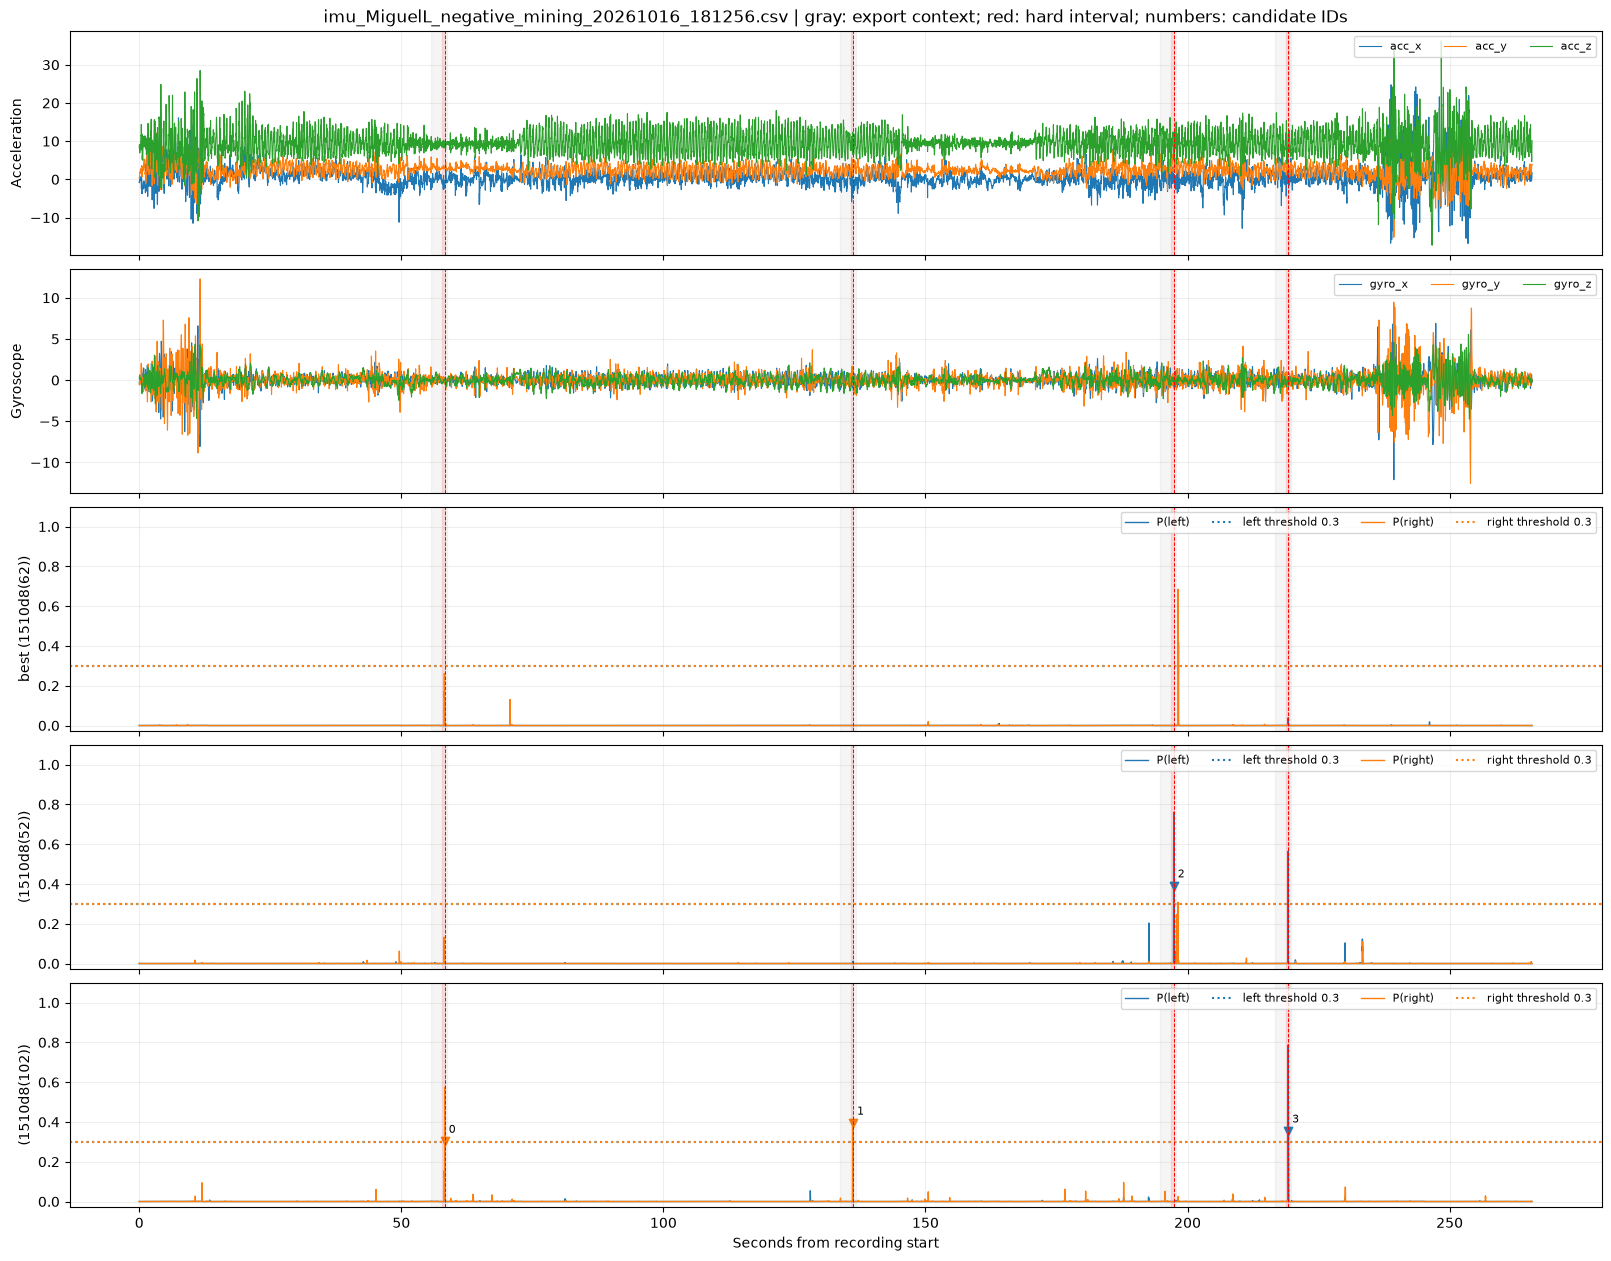

""


In [7]:
REVIEW_FILE = next(iter(batch_files), None)
REVIEW_CANDIDATE_ID = None
REVIEW_KEEP_IDS = []
SAVE_REVIEWED_CROPS = False
assert REVIEW_FILE in batch_files
review_candidates = batch_candidates[batch_candidates.file == REVIEW_FILE].copy()
assert len(REVIEW_KEEP_IDS) == len(set(REVIEW_KEEP_IDS))
assert set(REVIEW_KEEP_IDS) <= set(review_candidates.candidate_id)
display(batch_file_stats[batch_file_stats.file == REVIEW_FILE])
display(review_candidates)
recording = mining.load_recording(INPUT_DIR / REVIEW_FILE)
review_traces = {name: mining.predict_recording(recording, models[name], RESET_AT_SEGMENTS,
                                               FULL_INFERENCE_CHUNK_FRAMES) for name in BATCH_MODELS}
mining.plot_recording(recording, review_traces, batch_thresholds, review_candidates)
plt.show()
if REVIEW_CANDIDATE_ID is not None:
    assert REVIEW_CANDIDATE_ID in set(review_candidates.candidate_id)
    preview = review_candidates[review_candidates.candidate_id == REVIEW_CANDIDATE_ID]
    row = preview.iloc[0]
    display(preview)
    mining.plot_recording(recording, review_traces, batch_thresholds, preview,
                          int(row.crop_start_frame), int(row.crop_end_frame))
    plt.show()
reviewed = review_candidates[review_candidates.candidate_id.isin(REVIEW_KEEP_IDS)]
exports = (mining.export_batch(reviewed, models, INPUT_DIR, OUTPUT_DIR, BATCH_TRAINING_WINDOW_FRAMES)
           if SAVE_REVIEWED_CROPS else pd.DataFrame())
display(exports)
